# From a formula to a program: the falling skydiver

Companion notebook to *From Formulas to Programs* (ENG 101 Programming for Engineers, Nazarbayev University).

This notebook works through the running example of the book in Python. Run the cells from top to bottom. After each code cell, **predict** what will happen before you run it, **run** it, and **explain** the result to yourself.

## 1. The formula

A skydiver of mass $m$ falls from rest. Gravity pulls down with force $mg$; air drag pushes up with force $c v^2$. Newton's second law gives

$$ m\frac{dv}{dt} = mg - c v^2, \qquad v(0) = 0 . $$

The speed stops growing when the two forces balance. This terminal velocity is $v_\mathrm{t} = \sqrt{mg/c}$. The equation has the exact solution

$$ v(t) = v_\mathrm{t}\tanh\!\left(\frac{g t}{v_\mathrm{t}}\right), $$

which we will use to check the program.

## 2. The parameters

All values are in SI units. They are assumed teaching values, the same as in the book.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt

m = 80.0        # mass, kg
c = 0.25        # drag coefficient, kg/m
g = 9.81        # gravitational acceleration, m/s^2
t_end = 20.0    # final time, s

vt = math.sqrt(m * g / c)
print(f"Terminal velocity: {vt:.4f} m/s")

Terminal velocity: 56.0286 m/s


## 3. From the formula to an algorithm

Replace the derivative by a difference over a small time step $\Delta t$:

$$ \frac{v_{n+1}-v_n}{\Delta t} \approx g - \frac{c}{m}v_n^2
\quad\Longrightarrow\quad
v_{n+1} = v_n + \Delta t\left(g - \frac{c}{m}v_n^2\right). $$

This is the **explicit Euler method**. Starting from $v_0 = 0$, apply the update again and again. The function below does that for any right-hand side `f`.

In [2]:
def acceleration(v):
    """Right-hand side of the equation: dv/dt = g - (c/m) v^2."""
    return g - (c / m) * v**2


def exact_speed(t):
    """Exact solution; works for a number or a NumPy array."""
    return vt * np.tanh(g * t / vt)


def euler(f, v0, dt, t_end):
    """Solve dv/dt = f(v), v(0) = v0, up to t_end with steps of dt."""
    n_steps = round(t_end / dt)
    t = np.linspace(0.0, n_steps * dt, n_steps + 1)
    v = np.zeros(n_steps + 1)
    v[0] = v0
    for n in range(n_steps):
        v[n + 1] = v[n] + dt * f(v[n])
    return t, v

## 4. Run it and compare with the exact solution

The table shows every fourth step. It is the same table that every language chapter of the book prints.

In [3]:
t, v = euler(acceleration, 0.0, dt=0.5, t_end=t_end)

print(f"{'t (s)':>6} {'v_Euler':>10} {'v_exact':>10} {'error':>10}")
for n in range(0, len(t), 4):
    ve = exact_speed(t[n])
    print(f"{t[n]:6.1f} {v[n]:10.4f} {ve:10.4f} {v[n] - ve:10.2e}")

 t (s)    v_Euler    v_exact      error
   0.0     0.0000     0.0000   0.00e+00
   2.0    19.1034    18.8555   2.48e-01
   4.0    34.5926    33.8746   7.18e-01
   6.0    44.7434    43.8151   9.28e-01
   8.0    50.4431    49.6136   8.29e-01
  10.0    53.3562    52.7496   6.07e-01
  12.0    54.7717    54.3765   3.95e-01
  14.0    55.4423    55.2023   2.40e-01
  16.0    55.7562    55.6169   1.39e-01
  18.0    55.9022    55.8238   7.84e-02
  20.0    55.9700    55.9268   4.32e-02


## 5. Plot the result

Left: the speed. Right: the error of the Euler method, which is largest while the skydiver is still accelerating.

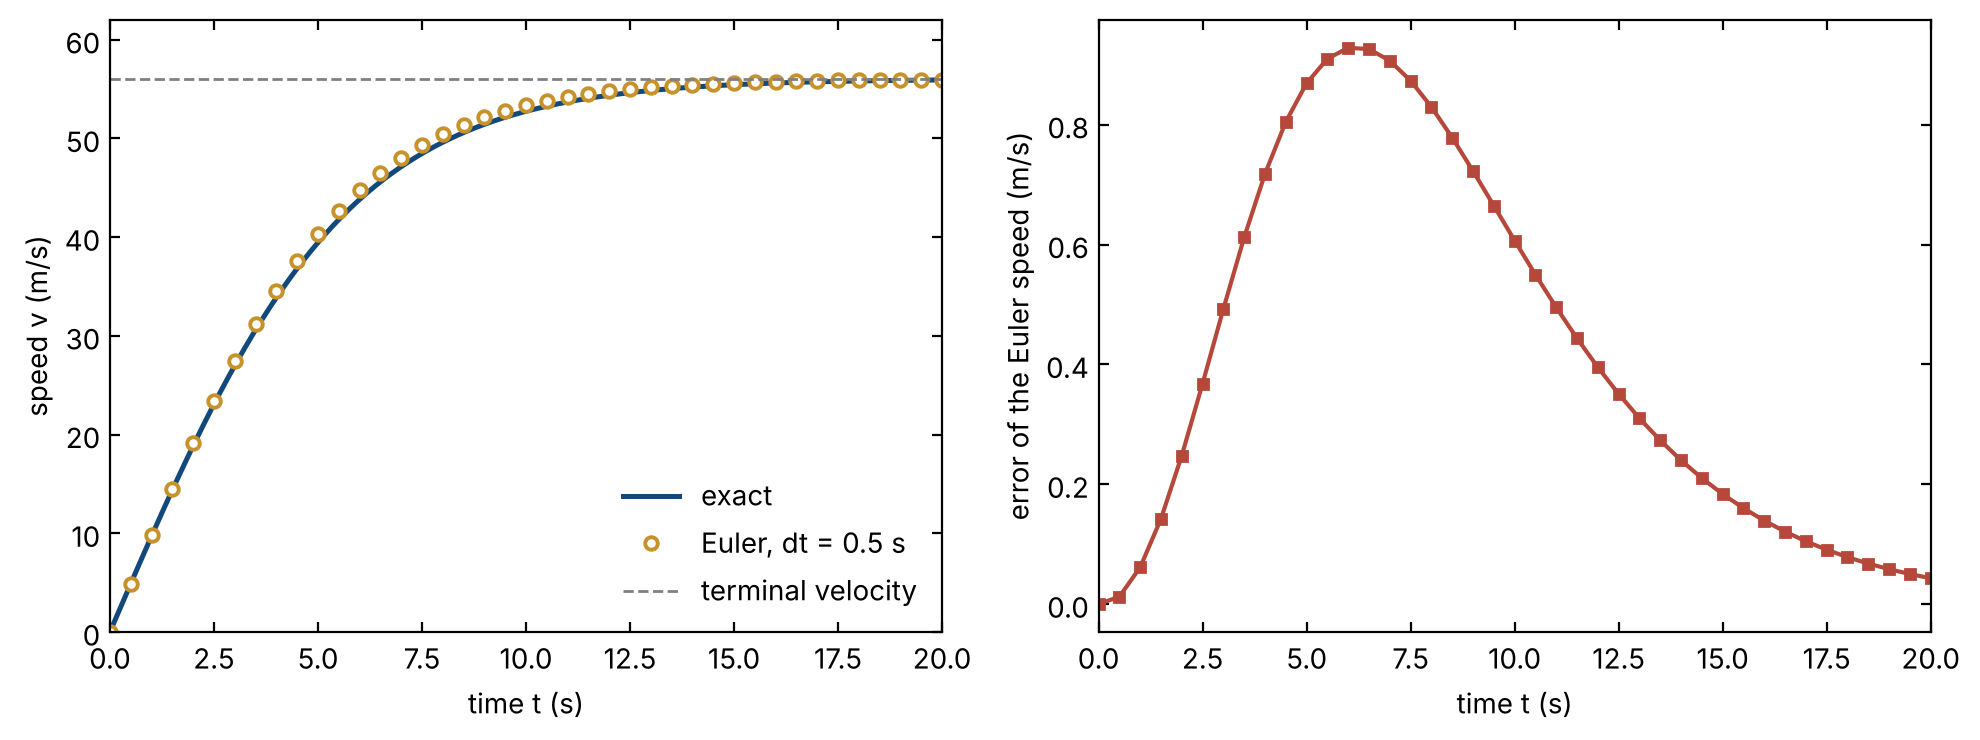

In [4]:
tf = np.linspace(0.0, t_end, 400)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.8))
ax1.plot(tf, exact_speed(tf), "-", color="#12497a", lw=1.8, label="exact")
ax1.plot(t, v, "o", ms=4.5, mfc="white", mec="#c8922a", mew=1.4, label="Euler, dt = 0.5 s")
ax1.axhline(vt, ls="--", color="gray", lw=1, label="terminal velocity")
ax1.set_xlabel("time t (s)")
ax1.set_ylabel("speed v (m/s)")
ax1.set_xlim(0, t_end)
ax1.set_ylim(0, 62)
ax1.legend(frameon=False, loc="lower right")

ax2.plot(t, v - exact_speed(t), "s-", ms=3.5, color="#b5483a")
ax2.set_xlabel("time t (s)")
ax2.set_ylabel("error of the Euler speed (m/s)")
ax2.set_xlim(0, t_end)

for ax in (ax1, ax2):
    ax.tick_params(direction="in", top=True, right=True)
fig.tight_layout()
plt.show()

## 6. How does the error depend on the time step?

A program that gives an answer is not yet a program you can trust. One standard check is to halve the time step and see how the error changes. For the Euler method the error should halve as well, because the method is *first-order accurate*.

In [5]:
steps = [0.5, 0.25, 0.125, 0.0625, 0.03125]
errors = []
print(f"{'dt (s)':>8} {'max error (m/s)':>16} {'ratio':>7}")
for dt in steps:
    t_k, v_k = euler(acceleration, 0.0, dt, t_end)
    err = np.max(np.abs(v_k - exact_speed(t_k)))
    ratio = errors[-1] / err if errors else float("nan")
    errors.append(err)
    print(f"{dt:8.5f} {err:16.5f} {ratio:7.2f}")

slope = np.polyfit(np.log(steps), np.log(errors), 1)[0]
print(f"Slope on log-log axes: {slope:.3f} (first order means a slope of 1)")

  dt (s)  max error (m/s)   ratio
 0.50000          0.92823     nan
 0.25000          0.45769    2.03
 0.12500          0.22716    2.01
 0.06250          0.11318    2.01
 0.03125          0.05649    2.00
Slope on log-log axes: 1.009 (first order means a slope of 1)


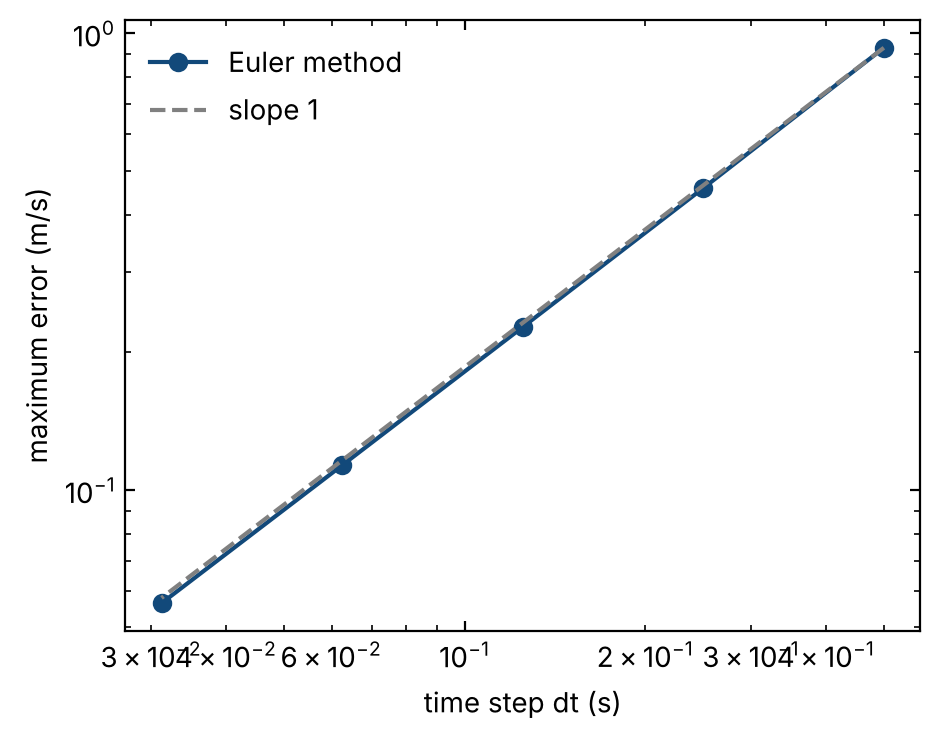

In [6]:
fig, ax = plt.subplots(figsize=(4.8, 3.8))
ax.loglog(steps, errors, "o-", color="#12497a", label="Euler method")
ax.loglog(steps, [errors[0] * s / steps[0] for s in steps], "--", color="gray", label="slope 1")
ax.set_xlabel("time step dt (s)")
ax.set_ylabel("maximum error (m/s)")
ax.tick_params(direction="in", top=True, right=True, which="both")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## 7. Two more checks

**A limiting case.** With no drag ($c = 0$) the speed must be $v = gt$ exactly. The Euler method reproduces a straight line without error, so the two numbers below must agree.

**A stability check.** If the time step is too large, the method fails. Try `dt = 12` and look at the numbers.

In [7]:
c_saved = c
c = 0.0                                    # switch the drag off
t0, v0 = euler(acceleration, 0.0, 0.5, 5.0)
print(f"No drag: v(5 s) = {v0[-1]:.6f} m/s, and g*t = {g * 5.0:.6f} m/s")
c = c_saved                                # switch the drag on again

t_bad, v_bad = euler(acceleration, 0.0, 12.0, 60.0)
print("dt = 12 s:", np.round(v_bad, 1))

No drag: v(5 s) = 49.050000 m/s, and g*t = 49.050000 m/s
dt = 12 s: [ 0.00000000e+00  1.17700000e+02 -2.84200000e+02 -3.19610000e+03
 -3.86148100e+05 -5.59202322e+09]


With a step of 12 s the computed speed jumps far above the terminal velocity, becomes negative and then runs away. Nothing in the program reported an error. This is why a numerical result must always be checked.

## 8. Try it yourself

1. Change the mass to 60 kg and to 100 kg. How does the terminal velocity change? Check that it scales with $\sqrt{m}$.
2. Replace the Euler update by Heun's method: compute `k1 = f(v[n])`, `k2 = f(v[n] + dt*k1)` and set `v[n+1] = v[n] + dt*(k1 + k2)/2`. Repeat the study of Section 6. What slope do you find now?
3. Add the height $h$ of the skydiver: $dh/dt = -v$, starting from 3000 m. When does the skydiver pass 1000 m?
4. Translate the function `euler` into one other language of the book and confirm that it prints the same table.